# Cool Sub-Neptunes (Bachelor project)

## Import libraries

In [1]:
import logging

import numpy as np
import optimistix as optx

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models

from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LogNorm

from scipy.interpolate import interp1d
import os

from matplotlib.ticker import ScalarFormatter

formatter = ScalarFormatter(useMathText=False)
formatter.set_scientific(False)
formatter.set_useOffset(False)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

import warnings
warnings.filterwarnings("ignore", category=UserWarning, module=r"labellines.*")
warnings.filterwarnings("ignore", category=UserWarning, module=r"matplotlib.*")

# Uncomment below to install labellines if not already installed
#!pip install matplotlib-label-lines

from labellines import labelLine, labelLines

Atmodeller initialized with double precision (float64)


# Model Setup

## Planet Parameters

In [29]:
# Mass 
Earth_mass = 5.972e24  # kg
planet_mass = 8.63 * Earth_mass # This can be varied between 1 and 10 Earth mass

# Radius
Earth_radius = 6371000  # metre
surface_radius = 1.02 * (planet_mass / Earth_mass)**(0.252) * Earth_radius # Calculate using the M-R relation from Hakim et al. (2018) Icarus
#surface_radius = 1.76 * 6.371e6 
# Surface temperature
surface_temperature = 1800  # Kelvin, temperature at the magma-atmosphere interface

# Atmosphere temperature
atmosphere_temperature = 500  # Kelvin, temperature at the top of the atmosphere, can be varied between 200-500K

# Extent of Magma Ocean: Full (mantle_melt_fraction = 1) or Partial (mantle_melt_fraction < 1)
mantle_melt_fraction = 1

# Oxygen fugacity at the surface (magma-atmosphere interface)
fO2_log10_shift = -3 # can vary between -6 and 0: np.linspace(-6, 0, number_of_realisations)  # IW-6 to IW

## Elemental Budgets

In [30]:
# Lodders et al. (2009) Springer Book Chapter - Table 8 (in wt%)

H_masspercent_lodders09: float = 73.9
He_masspercent_lodders09: float = 24.69
C_masspercent_lodders09: float = 0.22
N_masspercent_lodders09: float = 0.07
O_masspercent_lodders09: float = 0.63


# For envelope composition setup
number_of_realisations = 500
hmps = np.logspace(-1, 0, num=number_of_realisations)  # wt% H
h_kgs = hmps / 100 * planet_mass  # kg

# Lodders et al. (2009) Springer book chapter Table 8
o_kgs_solar = h_kgs * O_masspercent_lodders09 / H_masspercent_lodders09
c_kgs_solar = h_kgs * C_masspercent_lodders09 / H_masspercent_lodders09
n_kgs_solar = h_kgs * N_masspercent_lodders09 / H_masspercent_lodders09
he_kgs_solar = h_kgs * He_masspercent_lodders09 / H_masspercent_lodders09

# For atmosphere composition setup
atm_scalings = np.logspace(-10, 0, num=number_of_realisations)

h_kg = 1 / 100 * planet_mass  # kg for 1 wt% H

# Lodders et al. (2009) Springer book chapter Table 8
o_kg_solar = h_kg * O_masspercent_lodders09 / H_masspercent_lodders09
c_kg_solar = h_kg * C_masspercent_lodders09 / H_masspercent_lodders09
n_kg_solar = h_kg * N_masspercent_lodders09 / H_masspercent_lodders09
he_kg_solar = h_kg * He_masspercent_lodders09 / H_masspercent_lodders09

## Chemical Species Setup

In [31]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)

from atmodeller.solubility import NoSolubility

# Create CO with no solubility
CO_insoluble_rg = Species.create_gas( "CO", activity=get_eos_models()["CO_cs_shi92"])
CO_insoluble_g = Species.create_gas( "CO", solubility=NoSolubility())

# Create CO2 with no solubility  
CO2_insoluble_rgs = Species.create_gas("CO2", activity=get_eos_models()["CO2_cs_shi92"])
CO2_insoluble_gs = Species.create_gas("CO2", solubility=NoSolubility())

# Condensates
C_cr = Species.create_condensed("C", state="cr")
H2O_l = Species.create_condensed("H2O", state="l")
H2O_cr = Species.create_condensed("H2O", state="cr")

species_ideal_cond = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
        C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

species_real_cond = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
        C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
        #C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
        #C_cr,
        #H2O_cr,
        #H2O_l,
    )
)

In [32]:
#VARYING PLANET MASS HERE
planet_mass_Earths = np.linspace(4, 9, number_of_realisations)  # Vary linearly from 4-9 MEarth
planet_mass = planet_mass_Earths * 5.9722e24


# Fix Values for Linearly Varying Cases:
log10_H_frac = np.full(
    number_of_realisations, 0.5
)  # ~3% of planet mass, used for fix Surf Radius and Planet Mass cases
log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
fO2_log10_shifts = np.full(number_of_realisations, -3)


# Define the mass constraints dictionary
# Tried to tweak the mass constraints
mass_constraints = {
    "H": h_kg * 100,  # Much higher hydrogen
    "C": c_kg_solar * 100 * 100,  # 100x solar C/H ratio
    "O": o_kg_solar * 100,
    "N": n_kg_solar * 100,
    "He": he_kg_solar,
}


In [33]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [34]:
#tried more miltistart attempts
solver_parameters_multistart = SolverParameters(
    solver=optx.LevenbergMarquardt,
    max_steps=400,  # Increase iterations
    rtol=1e-5,      # Relax tolerance slightly
    atol=1e-8,
    multistart=100,  # Enable multistart for stability
)

In [35]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

model_ideal_varyMp_withsol = InteriorAtmosphere(species_ideal_cond)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyMp_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints={},
    solver_parameters=solver_parameters,
)
output_ideal_varyMp_withsol = model_ideal_varyMp_withsol.output

# Write the complete solution to Excel
output_ideal_varyMp_withsol.to_excel("ColdSubNeptune_varyMASS_IDEAL")

# Write the data to a pickle file with dataframes
output_ideal_varyMp_withsol.to_pickle("ColdSubNeptune_varyMASS_IDEAL")

[14:52:06 - atmodeller.classes             - INFO     ] - species = ('H2O_g: IdealGas, SolubilityPowerLaw', 'H2_g: IdealGas, SolubilityPowerLawLog10', 'O2_g: IdealGas, NoSolubility', 'CO2_g: IdealGas, _CO2_basalt_dixon95', 'CO_g: IdealGas, _CO_basalt_yoshioka19', 'CH4_g: IdealGas, _CH4_basalt_ardia13', 'N2_g: IdealGas, _N2_basalt_libourel03', 'H3N_g: IdealGas, NoSolubility', 'CHN_g: IdealGas, NoSolubility', 'He_g: IdealGas, SolubilityPowerLaw', 'C_cr: CondensateActivity, NoSolubility')
[14:52:06 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[14:52:06 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g',
 5: '2.0 CO_g = 1.0 CO2_g + 1.0 C_cr'}
[14:52:06 - atmodeller.classes    


Creating elemental budget plot vs. planet mass...

✓ Successfully saved: elemental_budget_vs_planet_mass.png


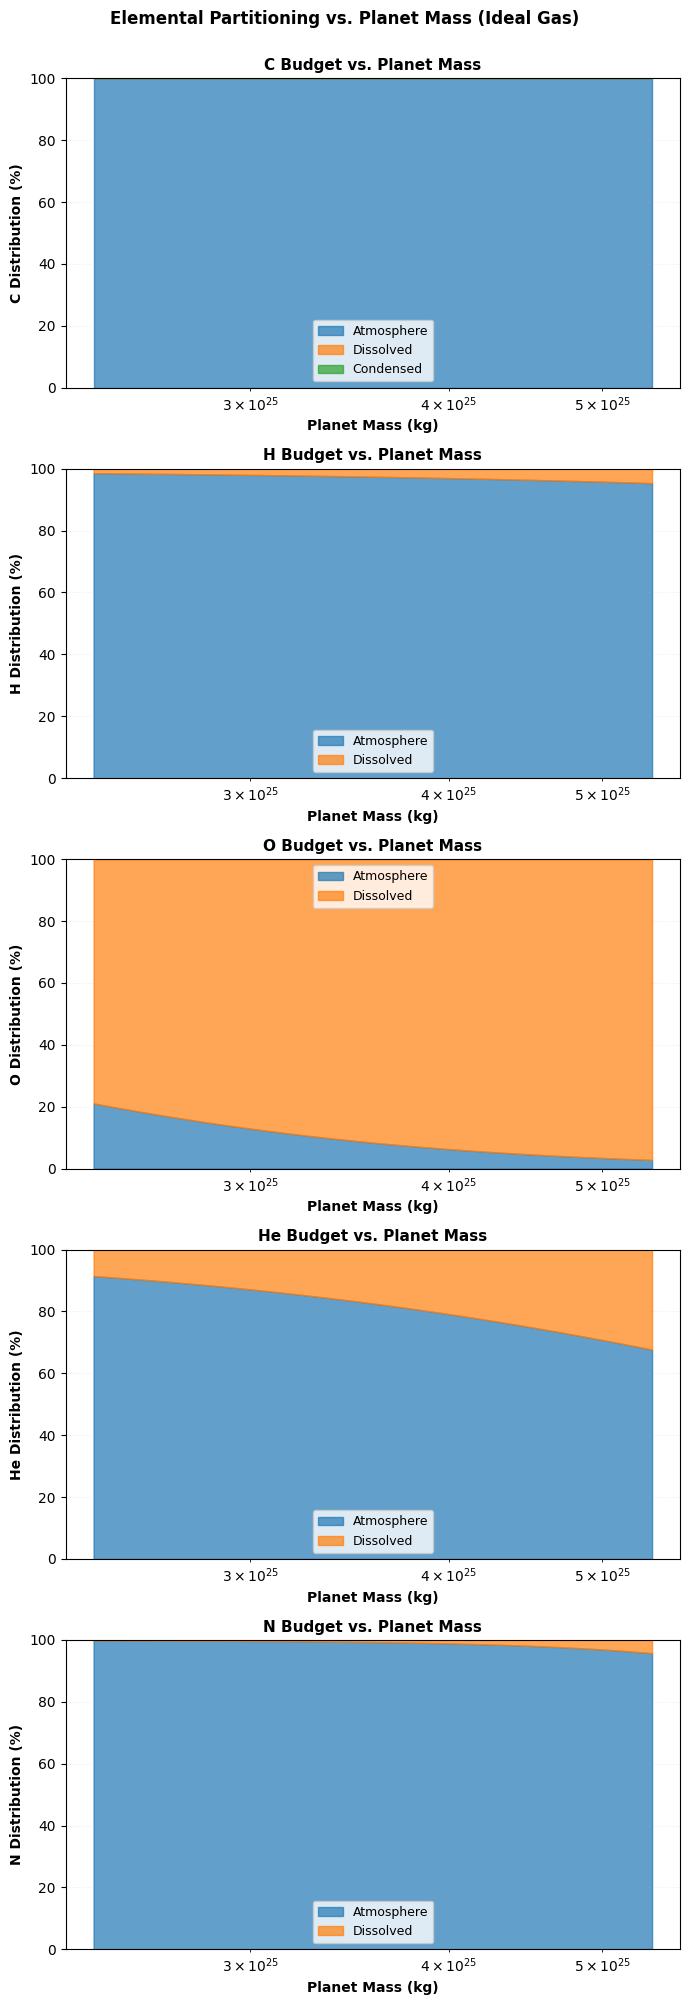

In [36]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_elemental_budget_vs_mp(elements=('C', 'H', 'O', 'He', 'N')):
    
    print("\n" + "="*70)
    print("Creating elemental budget plot vs. planet mass...")
    print("="*70)
    
    # Load planet mass and elemental data for real gas
    real_planet = pd.read_excel('ColdSubNeptune_varyMASS_IDEAL.xlsx', sheet_name='planet')
    planet_mass = real_planet['planet_mass']
    
    fig, axes = plt.subplots(5, 1, figsize=(7, 20))
    
    for idx, element in enumerate(elements):
        ax = axes[idx]
        sheet = f'element_{element}'
        df = pd.read_excel('ColdSubNeptune_varyMASS_IDEAL.xlsx', sheet_name=sheet)
        
        # Get mass components
        atm_mass = df.get('atmosphere_mass', pd.Series(np.zeros(len(df))))
        dis_mass = df.get('dissolved_mass', pd.Series(np.zeros(len(df))))
        con_mass = df.get('condensed_mass', pd.Series(np.zeros(len(df))))
        
        total_mass = atm_mass + dis_mass + con_mass
        
        # Avoid divide by zero
        total_mass[total_mass == 0] = np.nan
        
        atm_frac = atm_mass / total_mass * 100
        dis_frac = dis_mass / total_mass * 100
        con_frac = con_mass / total_mass * 100
        
        # Plot stacked area chart
        ax.fill_between(planet_mass, 0, atm_frac, label='Atmosphere', 
                       color='#1f77b4', alpha=0.7)
        ax.fill_between(planet_mass, atm_frac, atm_frac + dis_frac, 
                       label='Dissolved', color='#ff7f0e', alpha=0.7)
        if np.nanmax(con_frac) > 0:
            ax.fill_between(planet_mass, atm_frac + dis_frac, 100, 
                           label='Condensed', color='#2ca02c', alpha=0.7)
        
        ax.set_xscale('log')
        ax.set_ylim(0, 100)
        ax.set_xlabel('Planet Mass (kg)', fontsize=10, fontweight='bold')
        ax.set_ylabel(f'{element} Distribution (%)', fontsize=10, fontweight='bold')
        ax.set_title(f'{element} Budget vs. Planet Mass', fontsize=11, fontweight='bold')
        ax.legend(loc='best', frameon=True, fontsize=9)
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.5)
    
    plt.suptitle('Elemental Partitioning vs. Planet Mass (Ideal Gas)', 
                 fontsize=12, fontweight='bold', y=1)
    plt.tight_layout()
    plt.savefig('elemental_budget_vs_planet_mass.png', dpi=300, bbox_inches='tight')
    print("\n✓ Successfully saved: elemental_budget_vs_planet_mass.png")
    plt.show()

# Run the function
plot_elemental_budget_vs_mp(elements=('C', 'H', 'O', 'He', 'N'))


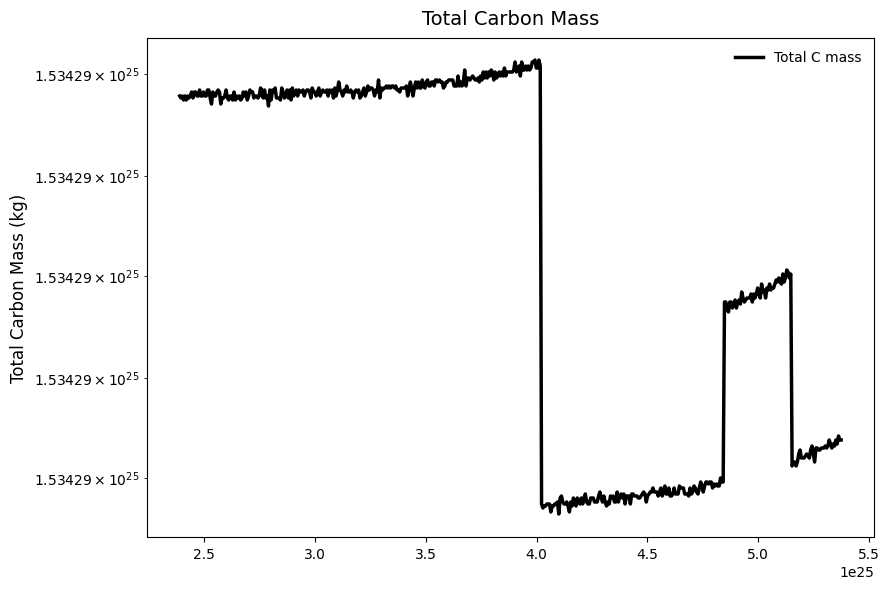

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# === Load the data ===
file_path = "ColdSubNeptune_varyMASS_IDEAL.xlsx"
planet = pd.read_excel(file_path, sheet_name="planet")
element_C = pd.read_excel(file_path, sheet_name="element_C")

df = pd.DataFrame({
    "planet_mass": planet["planet_mass"],
    "C_total": element_C["total_mass"],         # already includes all phases
    "C_condensed": element_C["condensed_mass"],
    "C_dissolved": element_C["dissolved_mass"],
    "C_atmosphere": element_C["atmosphere_mass"]
})

# === Create the figure ===
fig, ax1 = plt.subplots(figsize=(9,6))

# --- Left axis: total carbon mass ---
ax1.plot(df["planet_mass"], df["C_total"], color="black", lw=2.5, ls="-", label="Total C mass")
ax1.set_yscale("log")
ax1.set_ylabel("Total Carbon Mass (kg)", fontsize=12, color="black")
ax1.tick_params(axis="y", labelcolor="black")

# --- Legends & layout ---
handles1, labels1 = ax1.get_legend_handles_labels()
ax1.legend(handles1, labels1, loc="upper right", frameon=False)

plt.title("Total Carbon Mass", fontsize=14, pad=10)
plt.tight_layout()

# Uncomment to save
# plt.savefig("CarbonPartitioning_Composite.png", dpi=400, bbox_inches="tight")

plt.show()